## BIRTH Dataset

In [2]:
%pip install pandas matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
dataset=pd.read_csv("births.csv")

In [5]:
dataset.head()

,year,month,day,gender,births
0,1969,1,1.0,F,4046
1,1969,1,1.0,M,4440
2,1969,1,2.0,F,4454
3,1969,1,2.0,M,4548
4,1969,1,3.0,F,4548


In [6]:
dataset.describe()

,year,month,day,births
count,15547.000000,15547.000000,15067.000000,15547.000000
mean,1979.037435,6.515919,17.769894,9762.293561
std,6.728340,3.449632,15.284034,28552.465810
min,1969.000000,1.000000,1.000000,1.000000
25%,1974.000000,4.000000,8.000000,4358.000000
50%,1979.000000,7.000000,16.000000,4814.000000
75%,1984.000000,10.000000,24.000000,5289.500000
max,2008.000000,12.000000,99.000000,199622.000000


##### A pivot table is a data summarization tool that lets you reorganize and aggregate your data to see patterns easily.

#### Pivot table = group rows by year, split columns by gender, sum the births.

In [7]:
yearly_births = dataset.pivot_table(
    index='year',
    columns='gender',
    values='births',
    aggfunc='sum'
).reset_index()


# Sum of Column F , and M 
yearly_births['total_births'] = yearly_births['F'] + yearly_births['M']
yearly_births['different_in_births'] = yearly_births['M'] - yearly_births['F']


# Standard Deviation of both Column F and M in the End 
yearly_births['std_dev'] = yearly_births[['F', 'M']].std(axis=1)

# print(yearly_births)
print(yearly_births.describe())


gender         year             F             M  total_births  \
count     40.000000  4.000000e+01  4.000000e+01  4.000000e+01   
mean    1988.500000  1.850896e+06  1.943464e+06  3.794359e+06   
std       11.690452  1.646368e+05  1.697402e+05  3.343659e+05   
min     1969.000000  1.533102e+06  1.613023e+06  3.146125e+06   
25%     1978.750000  1.760253e+06  1.853284e+06  3.613537e+06   
50%     1988.500000  1.899796e+06  1.989806e+06  3.889602e+06   
75%     1998.250000  1.976348e+06  2.073878e+06  4.050226e+06   
max     2008.000000  2.111890e+06  2.212118e+06  4.324008e+06   

gender  different_in_births       std_dev  
count             40.000000     40.000000  
mean           92568.300000  65455.672653  
std             5784.928505   4090.562174  
min            79921.000000  56512.681059  
25%            89984.250000  63628.473375  
50%            92966.000000  65736.889020  
75%            97360.250000  68844.092993  
max           103311.000000  73051.908671  


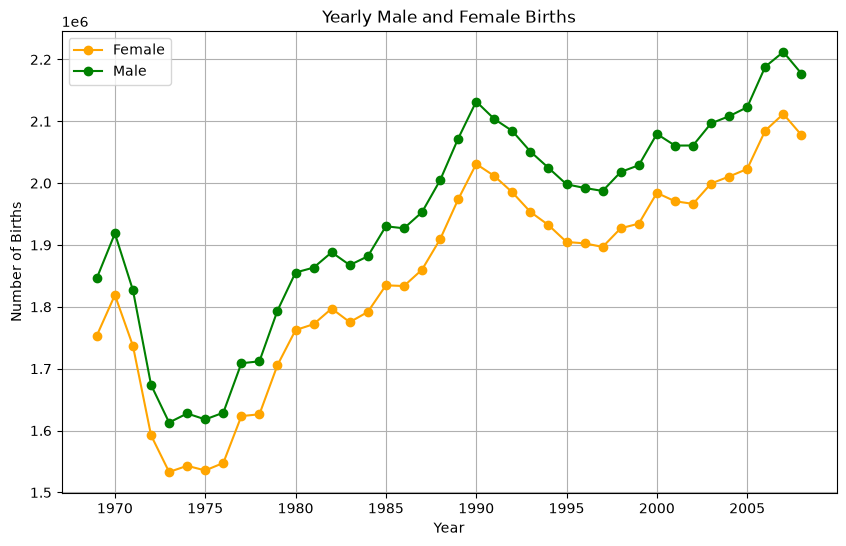

In [8]:
plt.figure(figsize=(10, 6))

# Plot Female births
plt.plot(yearly_births['year'], yearly_births['F'], marker='o', label='Female', color='orange')

# Plot Male births
plt.plot(yearly_births['year'], yearly_births['M'], marker='o', label='Male', color='green')

# Labels & title
plt.xlabel('Year')
plt.ylabel('Number of Births')
plt.title('Yearly Male and Female Births')
plt.legend()
plt.grid(True)
plt.show()


In [9]:
# Map day numbers to names
day_map = {1: "Monday", 2: "Tuesday", 3: "Wednesday", 4: "Thursday",
           5: "Friday", 6: "Saturday", 7: "Sunday"}
dataset['weekday'] = dataset['day'].map(day_map)

In [10]:
dataset.head()

,year,month,day,gender,births,weekday
0,1969,1,1.0,F,4046,Monday
1,1969,1,1.0,M,4440,Monday
2,1969,1,2.0,F,4454,Tuesday
3,1969,1,2.0,M,4548,Tuesday
4,1969,1,3.0,F,4548,Wednesday


In [11]:
weekday_births = dataset.pivot_table(
    index='weekday',
    columns='gender',
    values='births',
    aggfunc='sum'
)

# Reorder weekdays correctly
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_births = weekday_births.reindex(weekday_order)
print(weekday_births)


gender           F        M
weekday                    
Monday     1116209  1170645
Tuesday    1121757  1181411
Wednesday  1124014  1185073
Thursday   1115250  1171338
Friday     1121260  1175691
Saturday   1124184  1183889
Sunday     1126814  1187267


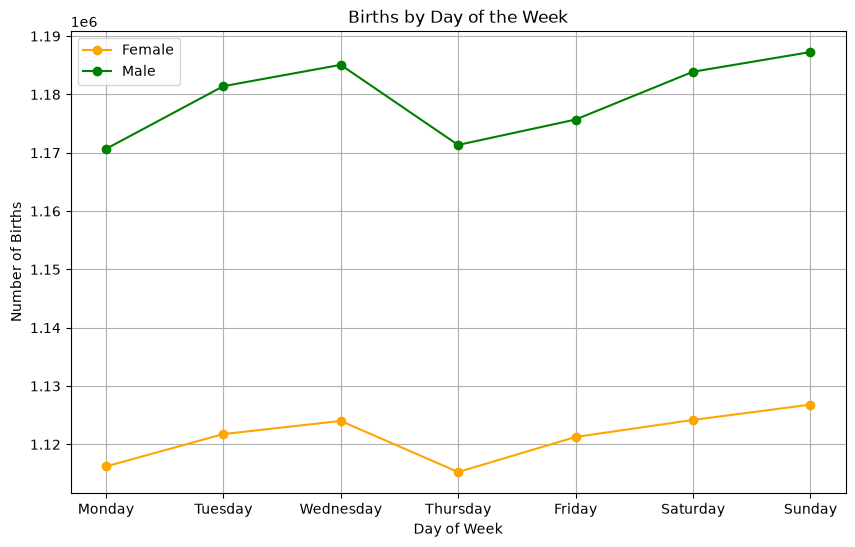

In [12]:
plt.figure(figsize=(10,6))
plt.plot(weekday_births.index, weekday_births['F'], marker='o', color='orange', label='Female')
plt.plot(weekday_births.index, weekday_births['M'], marker='o', color='green', label='Male')
plt.xlabel('Day of Week')
plt.ylabel('Number of Births')
plt.title('Births by Day of the Week')
plt.legend()
plt.grid(True)
plt.show()


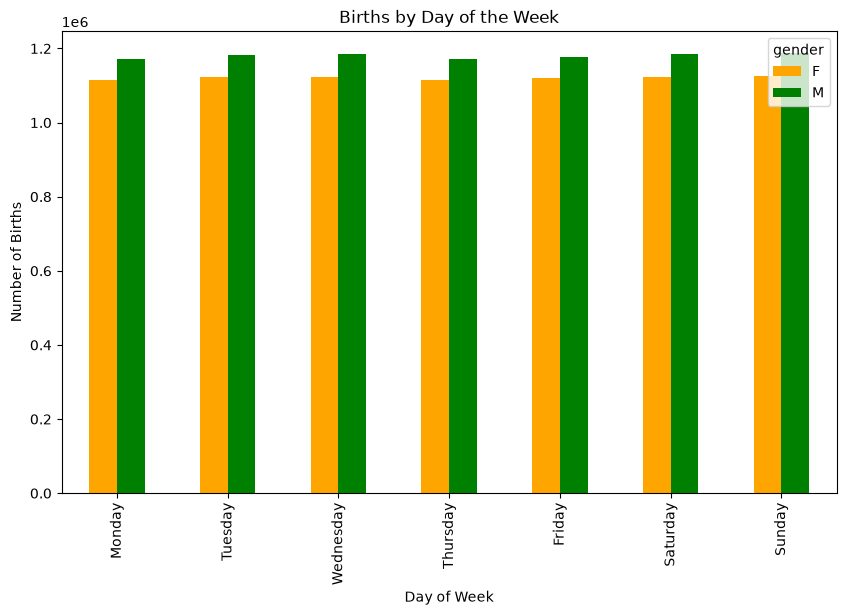

In [13]:
weekday_births.plot(kind='bar', figsize=(10,6), color=['orange','green'])
plt.xlabel('Day of Week')
plt.ylabel('Number of Births')
plt.title('Births by Day of the Week')
plt.show()


In [14]:
# Map day numbers to names
day_map = {1: "January", 2: "February", 3: "March", 4: "April",
           5: "May", 6: "June", 7: "July", 8: "August",
           9: "September", 10: "October", 11: "November", 12: "December"}
dataset['month_name'] = dataset['month'].map(day_map)

In [15]:
dataset.head()

,year,month,day,gender,births,weekday,month_name
0,1969,1,1.0,F,4046,Monday,January
1,1969,1,1.0,M,4440,Monday,January
2,1969,1,2.0,F,4454,Tuesday,January
3,1969,1,2.0,M,4548,Tuesday,January
4,1969,1,3.0,F,4548,Wednesday,January


In [16]:
# Assuming your dataset is called df
month_births = dataset.pivot_table(
    index='month_name',      # group by month
    columns='gender',   # separate columns for F and M
    values='births',
    aggfunc='sum'
).reset_index()


# Reorder weekdays correctly
month_order = ["January", "February", "March", "April", "May", "June", "July", "August", "September", "October", "November", "December"]
month_births = month_births.set_index('month_name').reindex(month_order).reset_index()
print(month_births)

gender month_name        F        M
0         January  6035447  6328750
1        February  5634064  5907114
2           March  6181613  6497231
3           April  5889345  6196546
4             May  6145186  6479786
5            June  6093026  6428044
6            July  6512299  6855257
7          August  6600723  6927284
8       September  6473029  6779802
9         October  6330549  6624401
10       November  5956388  6241579
11       December  6184154  6472761


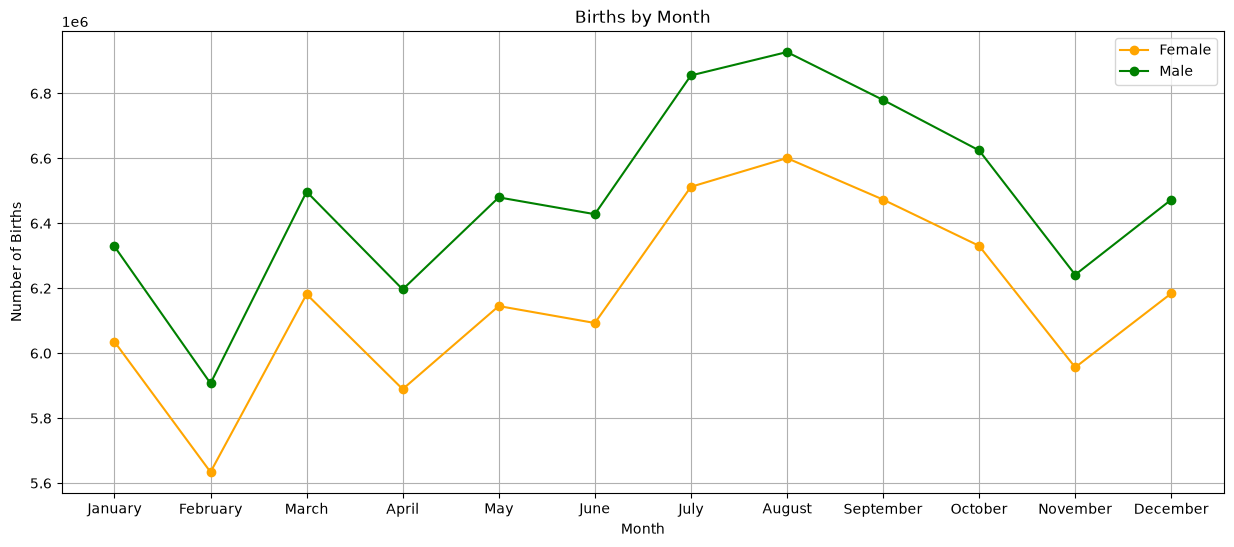

In [17]:
plt.figure(figsize=(15,6))
plt.plot(month_births['month_name'], month_births['F'], marker='o', color='orange', label='Female')
plt.plot(month_births['month_name'], month_births['M'], marker='o', color='green', label='Male')
plt.xlabel('Month')
plt.ylabel('Number of Births')
plt.title('Births by Month')
plt.legend()
plt.grid(True)
plt.show()


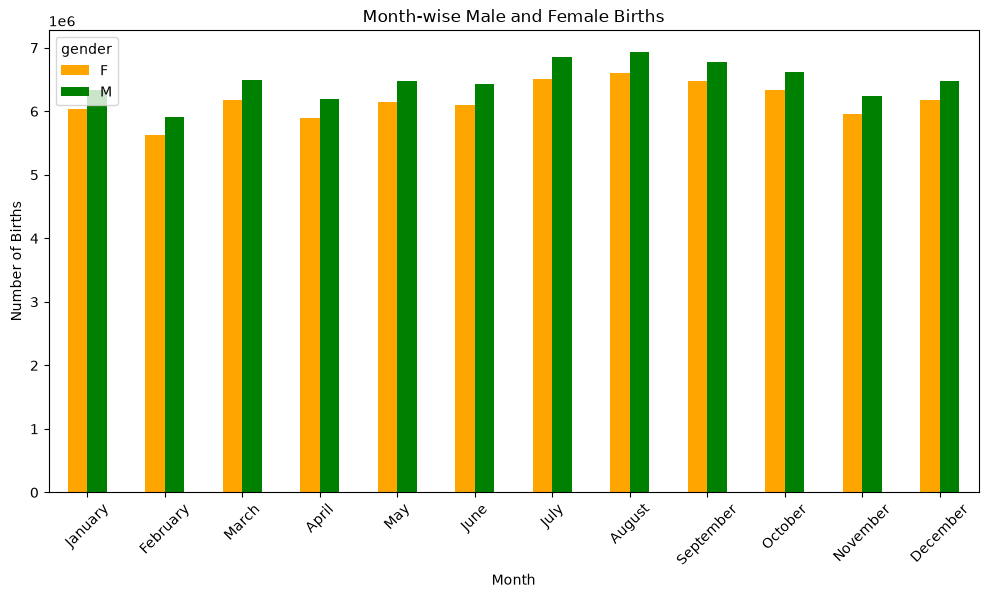

In [18]:
month_births.set_index('month_name')[['F','M']].plot(
    kind='bar',
    figsize=(12,6),
    color=['orange','green']
)

plt.xlabel('Month')
plt.ylabel('Number of Births')
plt.title('Month-wise Male and Female Births')
plt.xticks(rotation=45)
plt.show()


### Executive Summary

The dataset contains 15,547 records with the columns: year, month, day, gender, and births.

After performing analysis and visualizations:

The year with the highest number of births for both males and females is 2006.

The most common day of the week for births is Wednesday.

The month with the highest number of births is August.